In [1]:
# Packages
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.multioutput import RegressorChain
from sklearn.multioutput import MultiOutputRegressor

from sklearn.preprocessing import StandardScaler, RobustScaler

from pandas.tseries.offsets import DateOffset

import warnings 
warnings.filterwarnings('ignore')



from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score

## Loading the oil production data

In [2]:

# Read the CSV file into a DataFrame
data = pd.read_csv('ML_data.csv')


In [3]:
data.head()
# first five rows of data

,Period,Oil Production(bbl),Gas Production(MMscf),Gas Re-injected(MMscf)
0,1/1/18,2181529,3021.59,2631.47
1,2/1/18,1947711,2823.24,2367.69
2,3/1/18,2044780,3184.57,2247.01
3,4/1/18,1915683,3156.41,1468.90
4,5/1/18,1913518,3185.29,1728.87


In [4]:

# Convert Period column to datetime
data['Period'] = pd.to_datetime(data['Period'])

In [5]:
data

,Period,Oil Production(bbl),Gas Production(MMscf),Gas Re-injected(MMscf)
0,2018-01-01,2181529,3021.59,2631.47
1,2018-02-01,1947711,2823.24,2367.69
2,2018-03-01,2044780,3184.57,2247.01
3,2018-04-01,1915683,3156.41,1468.90
4,2018-05-01,1913518,3185.29,1728.87
...,...,...,...,...
67,2023-08-01,574256,3542.96,2423.19
68,2023-09-01,611204,3940.13,3053.78
69,2023-10-01,586893,4268.12,3354.42
70,2023-11-01,538056,4374.52,3705.63


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Period                  72 non-null     datetime64[ns]
 1   Oil Production(bbl)     72 non-null     int64         
 2   Gas Production(MMscf)   72 non-null     float64       
 3   Gas Re-injected(MMscf)  72 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 2.4 KB


In [7]:
data.describe()


,Period,Oil Production(bbl),Gas Production(MMscf),Gas Re-injected(MMscf)
count,72,7.200000e+01,72.000000,72.000000
mean,2020-12-15 15:20:00,1.263697e+06,4394.613750,3375.771528
min,2018-01-01 00:00:00,2.064710e+05,1237.580000,598.310000
25%,2019-06-23 12:00:00,7.104190e+05,3874.615000,2916.220000
50%,2020-12-16 12:00:00,1.244783e+06,4580.070000,3311.150000
75%,2022-06-08 12:00:00,1.778224e+06,4881.870000,3863.450000
max,2023-12-01 00:00:00,2.181529e+06,5771.430000,11796.320000
std,NaN,5.597066e+05,838.230895,1293.384409


In [8]:
df=data.drop(['Gas Production(MMscf)','Gas Re-injected(MMscf)', ], axis=1)

In [9]:
df

,Period,Oil Production(bbl)
0,2018-01-01,2181529
1,2018-02-01,1947711
2,2018-03-01,2044780
3,2018-04-01,1915683
4,2018-05-01,1913518
...,...,...
67,2023-08-01,574256
68,2023-09-01,611204
69,2023-10-01,586893
70,2023-11-01,538056


## Initial Plot of Data

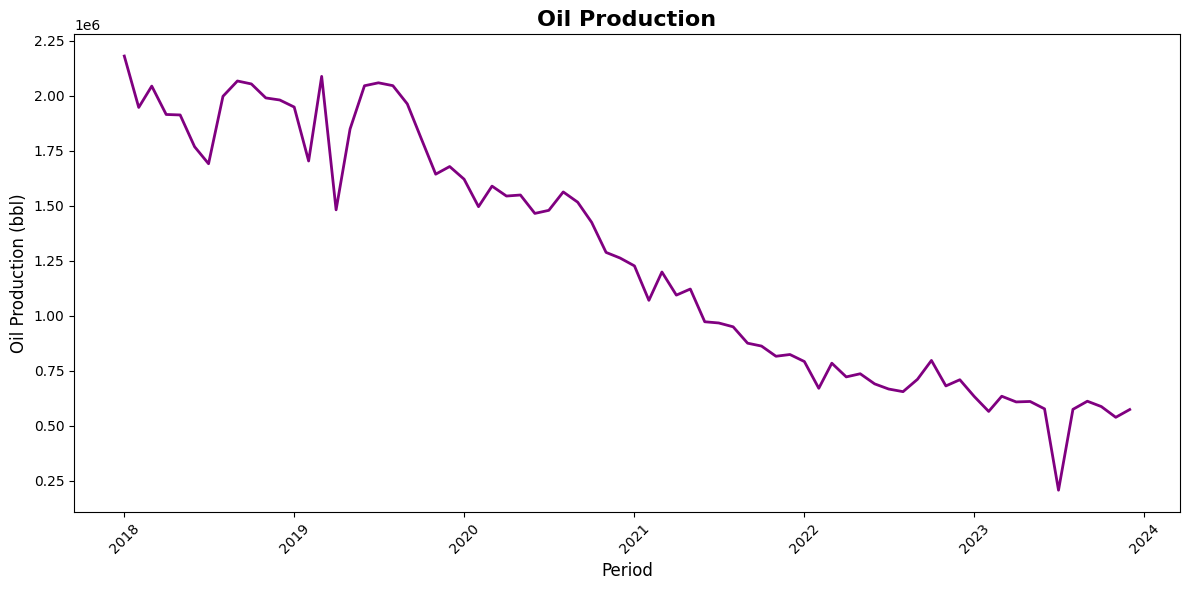

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6)) 
plt.plot(df['Period'], df['Oil Production(bbl)'], color='purple', linewidth=2)  
plt.title("Oil Production", fontsize=16, fontweight='bold')  # Bigger and bold title
plt.xlabel("Period", fontsize=12)
plt.ylabel("Oil Production (bbl)", fontsize=12)
plt.xticks(rotation=45)  # Rotate x-axis labels for clarity
plt.tight_layout()
plt.show()


#### *from the plot above, the oil production shows a decreasing trend*

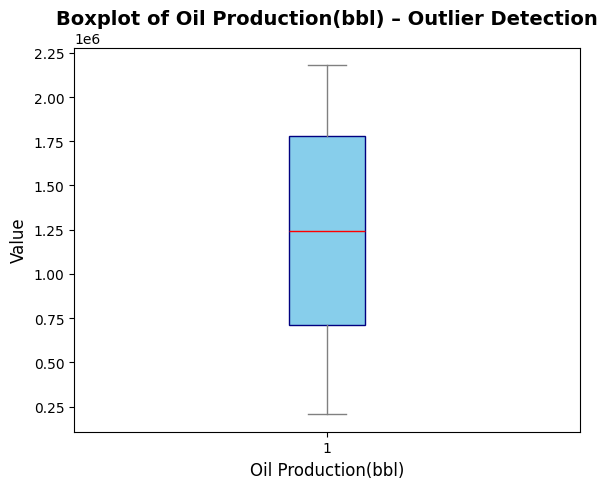

In [11]:
# For each numeric column, draw a separate boxplot
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    plt.figure(figsize=(6, 5))  # Bigger and better aspect ratio
    plt.boxplot(df[col].dropna(), patch_artist=True, boxprops=dict(facecolor='skyblue', color='navy'),
                medianprops=dict(color='red'), whiskerprops=dict(color='gray'), capprops=dict(color='gray'))
    plt.title(f"Boxplot of {col} – Outlier Detection", fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Value", fontsize=12)
    plt.tight_layout()
    plt.show()


## Start of ARIMA

# Step 1: Check for stationarity of time series

In [12]:
from statsmodels.tsa.stattools import adfuller

ts = df.set_index('Period')['Oil Production(bbl)']
result = adfuller(ts)
print('ADF Statistic:', result[0])
print('p-value:', result[1])

if result[1] < 0.05:
    print('Time series is stationary')
else:
    print('Time series is NOT stationary. You need to difference it.')
    
print('-------------------------------------------------------------')

print(result)
# Print test statistic (0th value should be more negative for stationarity)


ADF Statistic: -0.7958030344503034
p-value: 0.8203517868291383
Time series is NOT stationary. You need to difference it.
-------------------------------------------------------------
(-0.7958030344503034, 0.8203517868291383, 1, 70, {'1%': -3.5274258688046647, '5%': -2.903810816326531, '10%': -2.5893204081632653}, 1560.3030208683685)


#### Making data sta..

In [13]:

ts_diff = ts.diff().dropna()


In [14]:
result_diff = adfuller(ts_diff)
print('ADF Statistic:', result_diff[0])
print('p-value:', result_diff[1])

if result_diff[1] < 0.05:
    print('Time series is stationary')
else:
    print('Time series is NOT stationary. You need to difference it.')
    
print('-------------------------------------------------------------')

print(result_diff)
# Print test statistic (0th value should be more negative for stationarity)


ADF Statistic: -13.466991382004164
p-value: 3.440979544422417e-25
Time series is stationary
-------------------------------------------------------------
(-13.466991382004164, 3.440979544422417e-25, 0, 70, {'1%': -3.5274258688046647, '5%': -2.903810816326531, '10%': -2.5893204081632653}, 1531.2908062515185)


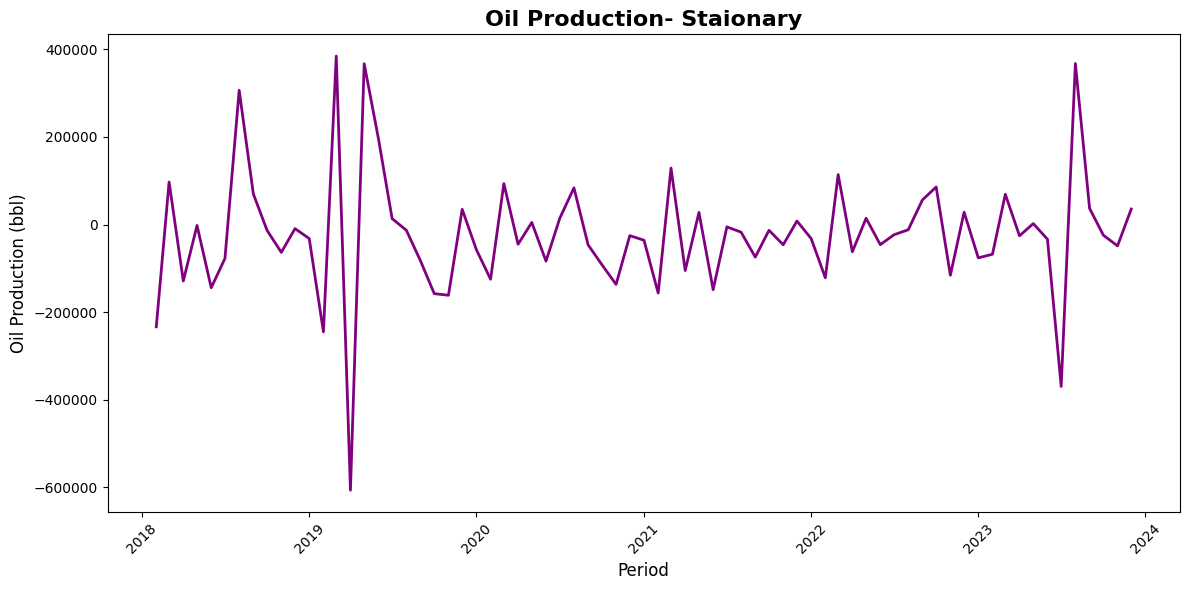

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6)) 
plt.plot( ts_diff, color='purple', linewidth=2)  
plt.title("Oil Production- Staionary", fontsize=16, fontweight='bold')  # Bigger and bold title
plt.xlabel("Period", fontsize=12)
plt.ylabel("Oil Production (bbl)", fontsize=12)
plt.xticks(rotation=45)  # Rotate x-axis labels for clarity
plt.tight_layout()
plt.show()


### Fitting our ARIMA

####  Determining the p,d,q

<Figure size 1200x600 with 0 Axes>

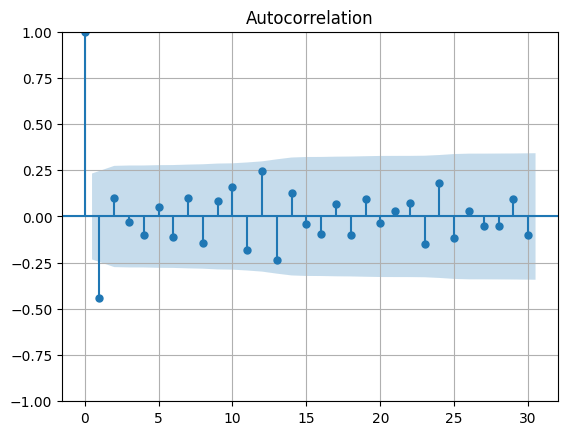

<Figure size 1200x600 with 0 Axes>

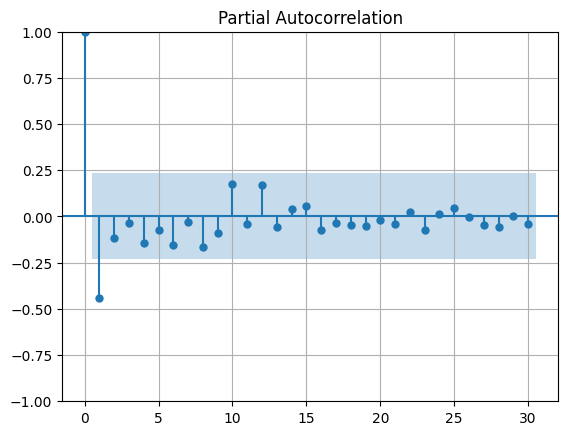

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plot_acf(ts_diff, lags=30)
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plot_pacf(ts_diff, lags=30)
plt.grid(True)
plt.show()


In [17]:
ts_diff

Period
2018-02-01   -233818.0
2018-03-01     97069.0
2018-04-01   -129097.0
2018-05-01     -2165.0
2018-06-01   -144472.0
                ...   
2023-08-01    367785.0
2023-09-01     36948.0
2023-10-01    -24311.0
2023-11-01    -48837.0
2023-12-01     35347.0
Name: Oil Production(bbl), Length: 71, dtype: float64

In [18]:
from pmdarima import auto_arima

stepwise_model = auto_arima(ts_diff, stepwise=False, seasonal=False, trace=True)
stepwise_model


 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1893.131, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=1882.670, Time=0.02 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=1883.971, Time=0.03 sec
 ARIMA(0,0,3)(0,0,0)[0]             : AIC=1885.423, Time=0.04 sec
 ARIMA(0,0,4)(0,0,0)[0]             : AIC=1891.429, Time=0.05 sec
 ARIMA(0,0,5)(0,0,0)[0]             : AIC=1898.595, Time=0.08 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=1881.872, Time=0.02 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=1883.639, Time=0.04 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=1885.758, Time=0.05 sec
 ARIMA(1,0,3)(0,0,0)[0]             : AIC=1887.759, Time=0.15 sec
 ARIMA(1,0,4)(0,0,0)[0]             : AIC=1893.120, Time=0.14 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=1883.624, Time=0.02 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=1885.269, Time=0.08 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=1887.339, Time=0.14 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=inf, Time=0.23 sec
 ARIMA(3,0,0)(0

ARIMA(order=(1, 0, 0), scoring_args={}, suppress_warnings=True,
      with_intercept=False)

In [19]:
from statsmodels.tsa.arima.model import ARIMA


model = ARIMA(ts_diff, order=(1,0,0))
model_fit = model.fit()

print(model_fit.summary())



                                SARIMAX Results                                
Dep. Variable:     Oil Production(bbl)   No. Observations:                   71
Model:                  ARIMA(1, 0, 0)   Log Likelihood                -936.926
Date:                 Tue, 22 Jul 2025   AIC                           1879.852
Time:                         08:58:54   BIC                           1886.640
Sample:                     02-01-2018   HQIC                          1882.552
                          - 12-01-2023                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.265e+04   1.12e+04     -2.018      0.044   -4.46e+04    -655.605
ar.L1         -0.4477      0.060     -7.413      0.000      -0.566      -0.329
sigma2      1.664e+10      0.005    3.1e+12 

C:\Users\DEON\anaconda3\envs\Tensorfloww\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\DEON\anaconda3\envs\Tensorfloww\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\DEON\anaconda3\envs\Tensorfloww\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


### one step forcasting

In [20]:
# Generate predictions
one_step_forecast = model_fit.get_prediction(start=-30)

# Extract prediction mean
mean_forecast = one_step_forecast.predicted_mean

# Get confidence intervals of predictions
confidence_intervals = one_step_forecast.conf_int()

# Inspect actual column names (optional)
# print(confidence_intervals.columns)

# Extract lower/upper bounds using actual column names
lower_limits = confidence_intervals.iloc[:, 0]
upper_limits = confidence_intervals.iloc[:, 1]

# Print best estimate predictions
print(mean_forecast)

2021-07-01     33891.476343
2021-08-01    -30338.887871
2021-09-01    -24974.455961
2021-10-01       556.515006
2021-11-01    -26897.359905
2021-12-01    -12042.870975
2022-01-01    -36345.780121
2022-02-01    -18489.859751
2022-03-01     21725.471275
2022-04-01    -83913.812304
2022-05-01     -4879.997821
2022-06-01    -39193.200164
2022-07-01    -12178.974071
2022-08-01    -22321.788704
2022-09-01    -27410.432761
2022-10-01    -57949.908133
2022-11-01    -71187.277378
2022-12-01     19097.875641
2023-01-01    -45396.188322
2023-02-01      1333.287612
2023-03-01     -2394.773189
2023-04-01    -63695.786879
2023-05-01    -21214.607923
2023-06-01    -33715.498242
2023-07-01    -17766.364344
2023-08-01    132880.959624
2023-09-01   -197450.209424
2023-10-01    -49331.985428
2023-11-01    -21905.868387
2023-12-01    -10925.392921
Freq: MS, Name: predicted_mean, dtype: float64


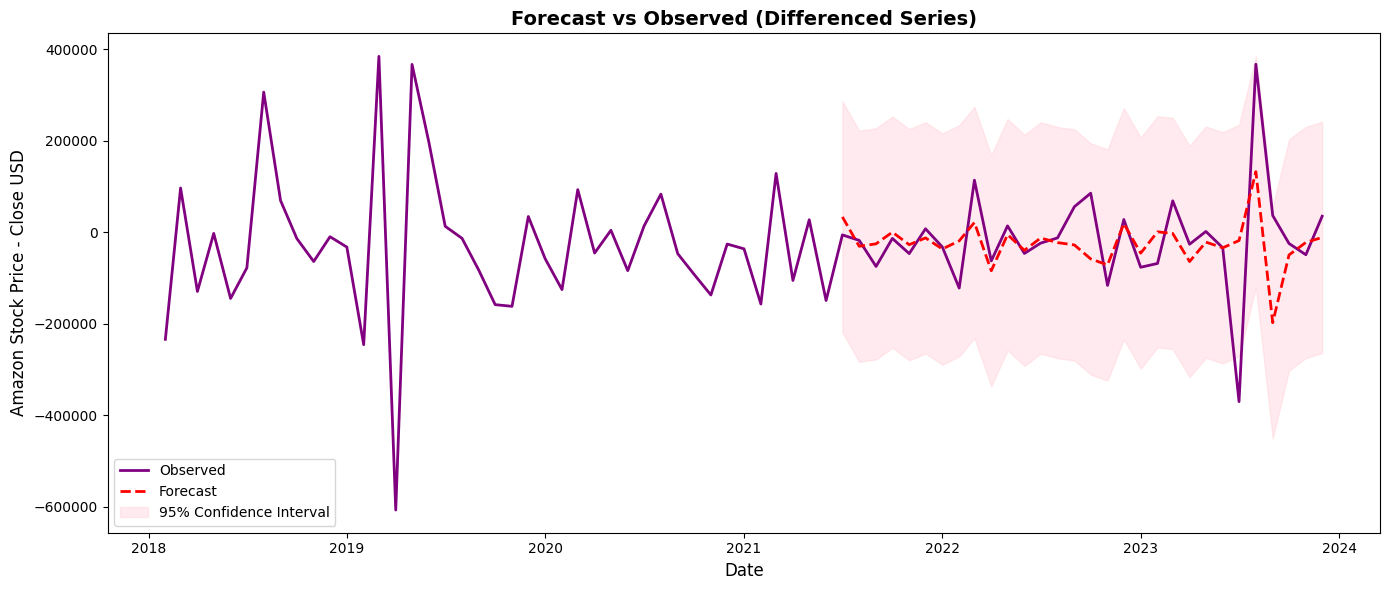

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))  # Wider and more readable

# Plot the observed differenced data
plt.plot(ts_diff, label='Observed', color='purple', linewidth=2)

# Plot forecasted mean
plt.plot(mean_forecast.index, mean_forecast, color='red', linestyle='--', linewidth=2, label='Forecast')

# Shade the confidence interval
plt.fill_between(lower_limits.index, lower_limits, upper_limits, color='pink', alpha=0.3, label='95% Confidence Interval')

# Add labels, legend, and grid
plt.xlabel('Date', fontsize=12)
plt.ylabel('Amazon Stock Price - Close USD', fontsize=12)
plt.title('Forecast vs Observed (Differenced Series)', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
# Make ARIMA forecast of next 10 values
arima_value_forecast = model_fit.get_forecast(steps=30).predicted_mean

# Print forecast
print(arima_value_forecast)

2024-01-01   -48615.205635
2024-02-01   -11024.691933
2024-03-01   -27854.248871
2024-04-01   -20319.529102
2024-05-01   -23692.880059
2024-06-01   -22182.605353
2024-07-01   -22858.766747
2024-08-01   -22556.044184
2024-09-01   -22691.575362
2024-10-01   -22630.897030
2024-11-01   -22658.063178
2024-12-01   -22645.900688
2025-01-01   -22651.345926
2025-02-01   -22648.908052
2025-03-01   -22649.999507
2025-04-01   -22649.510854
2025-05-01   -22649.729628
2025-06-01   -22649.631681
2025-07-01   -22649.675533
2025-08-01   -22649.655900
2025-09-01   -22649.664690
2025-10-01   -22649.660754
2025-11-01   -22649.662516
2025-12-01   -22649.661728
2026-01-01   -22649.662081
2026-02-01   -22649.661923
2026-03-01   -22649.661993
2026-04-01   -22649.661962
2026-05-01   -22649.661976
2026-06-01   -22649.661969
Freq: MS, Name: predicted_mean, dtype: float64


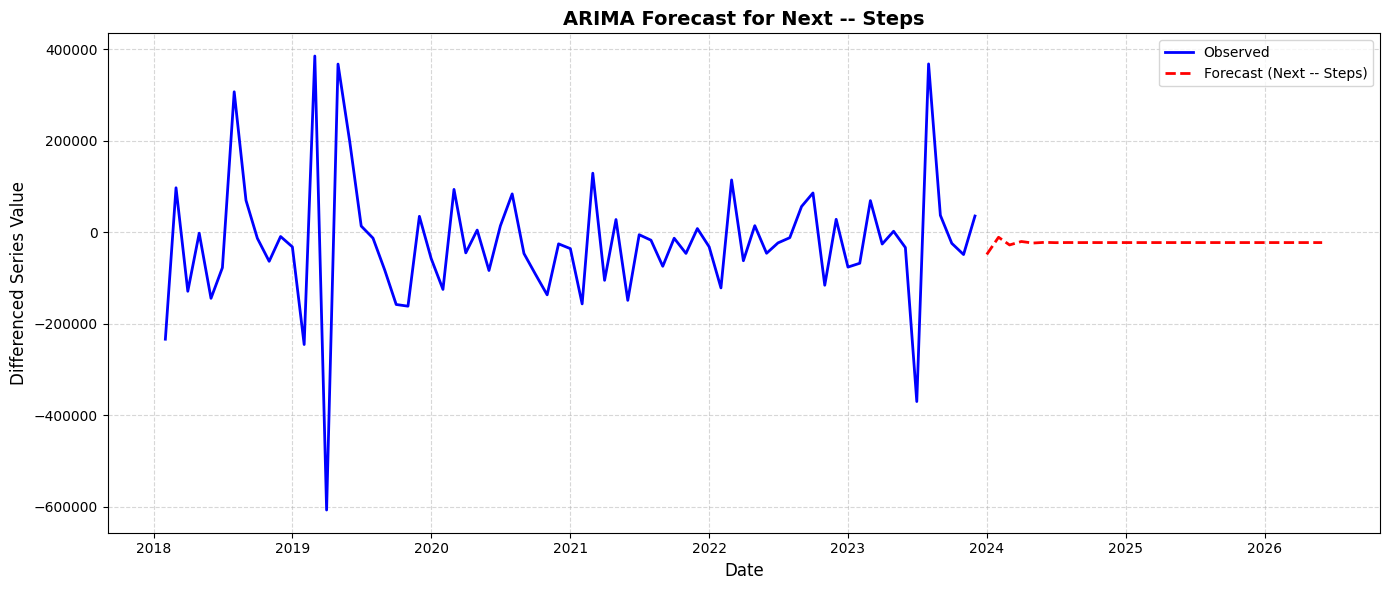

In [23]:
import matplotlib.pyplot as plt

# Combine observed and forecast for plotting
full_series = pd.concat([ts_diff, arima_value_forecast])

# Create the plot
plt.figure(figsize=(14, 6))
plt.plot(ts_diff, label='Observed', color='blue', linewidth=2)
plt.plot(arima_value_forecast.index, arima_value_forecast, color='red', linestyle='--', linewidth=2, label='Forecast (Next -- Steps)')

# Labels and style
plt.title('ARIMA Forecast for Next -- Steps', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Differenced Series Value', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA


# Calculate the mean absolute error from residuals
mae = np.mean(np.abs(model_fit.resid))

# Print mean absolute error
print('MAE:',mae)



MAE: 87115.62465660892


In [25]:
residuals = pd.Series(model_fit.resid)
actual     = ts

mape = (np.abs(residuals / actual)).mean() * 100
print(f"MAPE: {mape:.2f}%")

MAPE: 9.27%


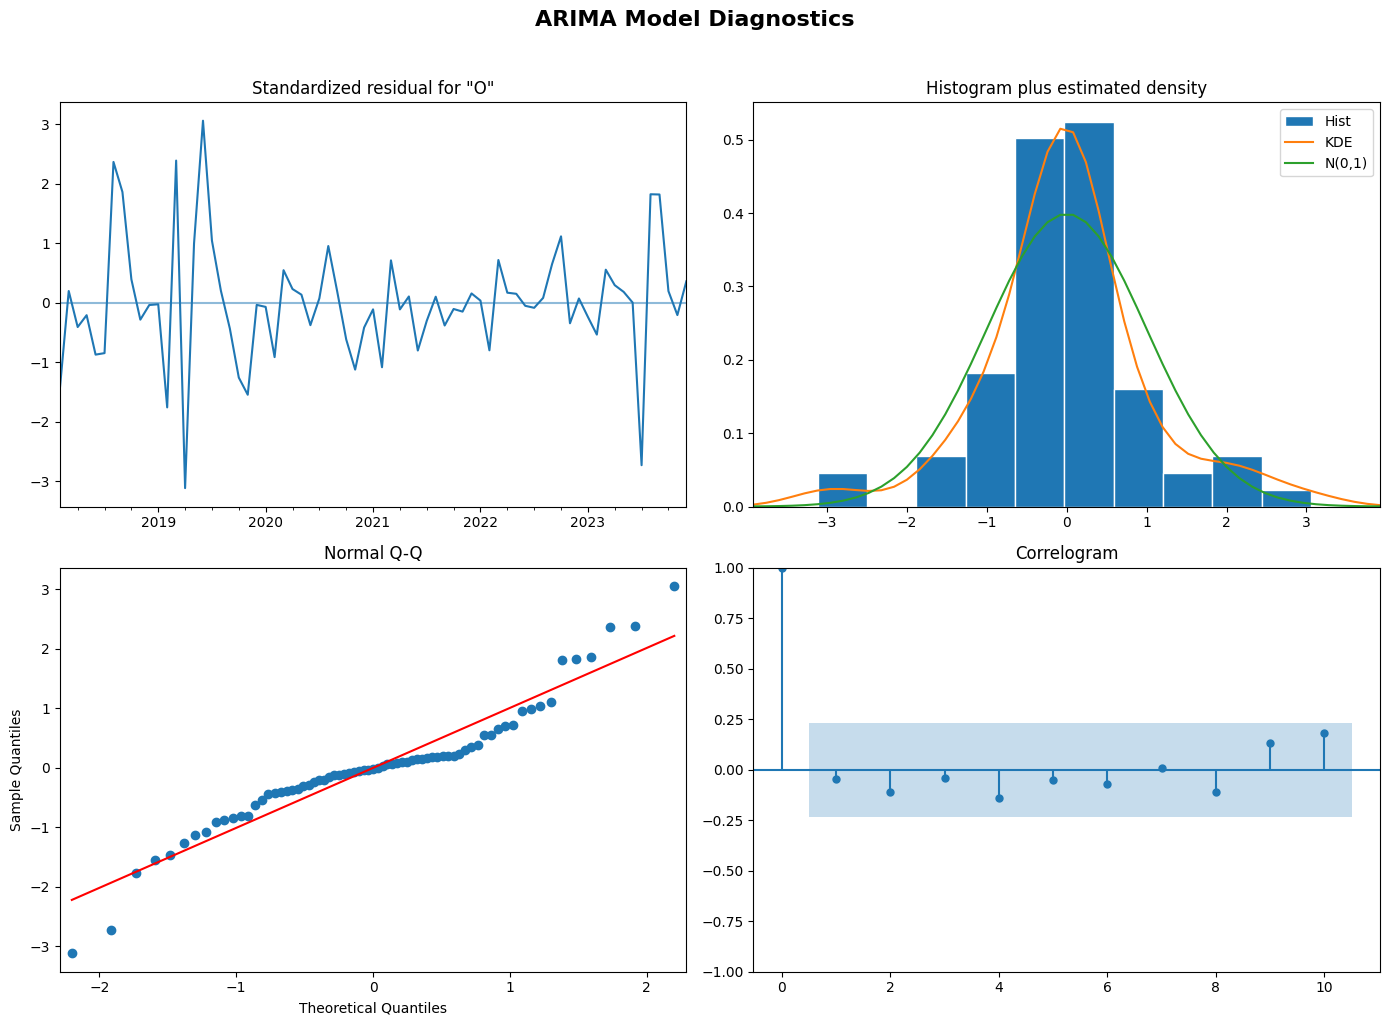

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns


# Plot ARIMA diagnostics
fig = model_fit.plot_diagnostics(figsize=(14, 10))

# Add a title above all subplots
fig.suptitle('ARIMA Model Diagnostics', fontsize=16, fontweight='bold', y=1.02)

# Ensure nothing is cut off
plt.tight_layout()
plt.show()


In [27]:
# 1) Grab the last observed value of the original series
last_orig = ts.iloc[-1]


forecast_cumsum = arima_value_forecast.cumsum()

forecast_undiff = last_orig + forecast_cumsum

print(forecast_undiff.head())


2024-01-01    524787.794365
2024-02-01    513763.102432
2024-03-01    485908.853561
2024-04-01    465589.324459
2024-05-01    441896.444401
Freq: MS, Name: predicted_mean, dtype: float64


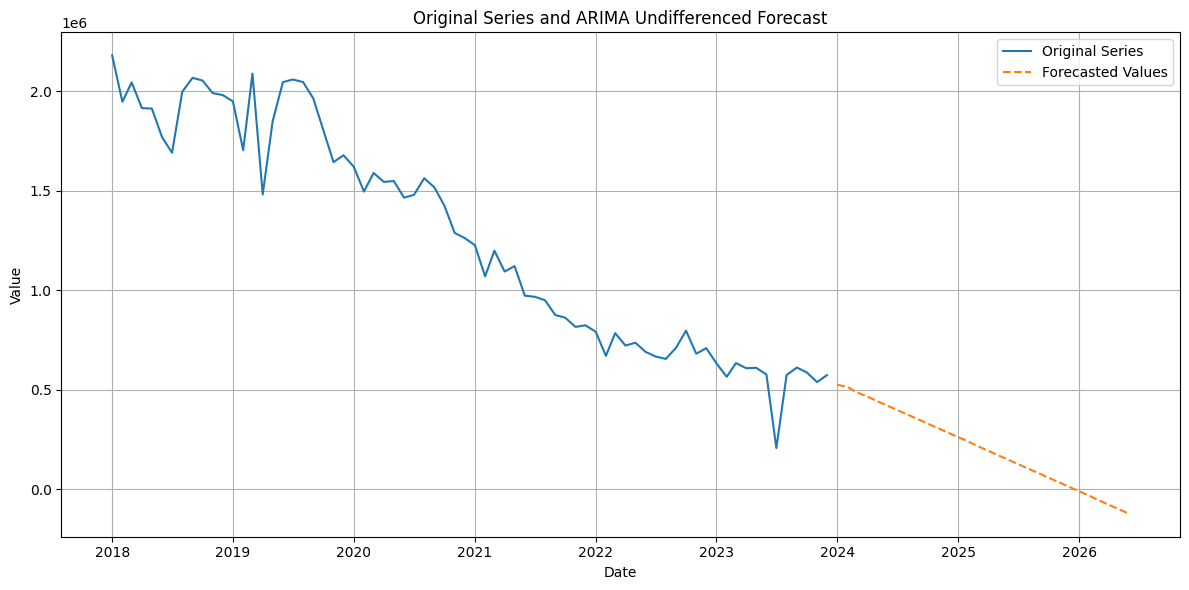

In [28]:
import matplotlib.pyplot as plt

# === PLOT: Original Series and Undifferenced Forecast ===
plt.figure(figsize=(12, 6))
plt.plot(ts, label='Original Series')
plt.plot(forecast_undiff, linestyle='--', label='Forecasted Values')
plt.title('Original Series and ARIMA Undifferenced Forecast')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### **Seasonal Arima**

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error


In [30]:
# 1. Parse 'Period' to datetime
df['Period'] = pd.to_datetime(df['Period'], errors='coerce')

# 2. Drop rows where 'Period' or 'Oil Production(bbl)' is missing
df = df.dropna(subset=['Period', 'Oil Production(bbl)'])

# 3. Set the Period column as index
df = df.set_index('Period').sort_index()

# 4. Ensure monthly frequency ('MS' = Month Start)
df = df.asfreq('MS')

# 5. Optional: Convert to a clean Series for modeling
y = df['Oil Production(bbl)'].dropna()


In [31]:
df

,Oil Production(bbl)
Period,
2018-01-01,2181529
2018-02-01,1947711
2018-03-01,2044780
2018-04-01,1915683
2018-05-01,1913518
...,...
2023-08-01,574256
2023-09-01,611204
2023-10-01,586893


<Figure size 1200x600 with 0 Axes>

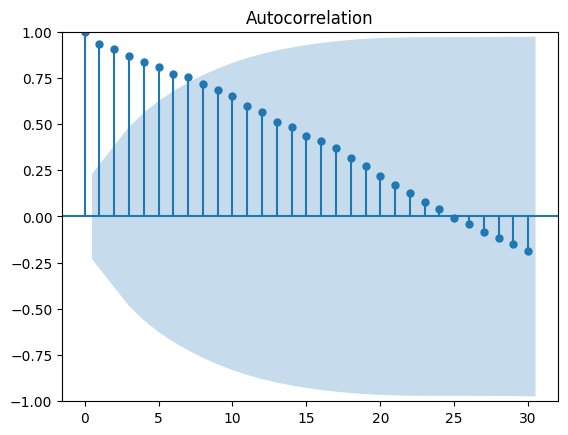

In [32]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plot_acf(df, lags=30)

plt.show()


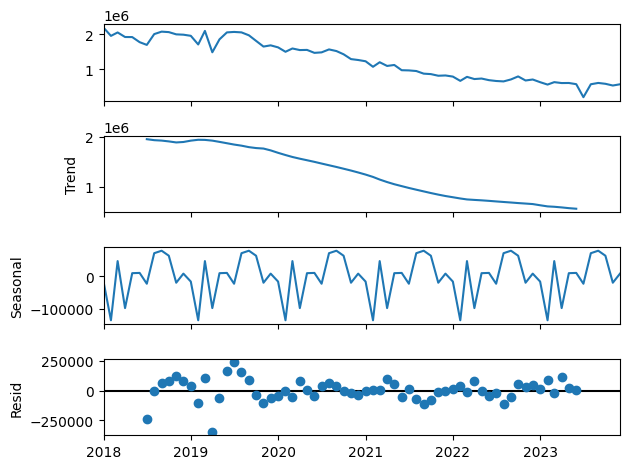

In [33]:
# Import seasonal decompose
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive decomposition
decomp = seasonal_decompose(df, 
                            period=12)

# Plot decomposition
decomp.plot()
plt.show()


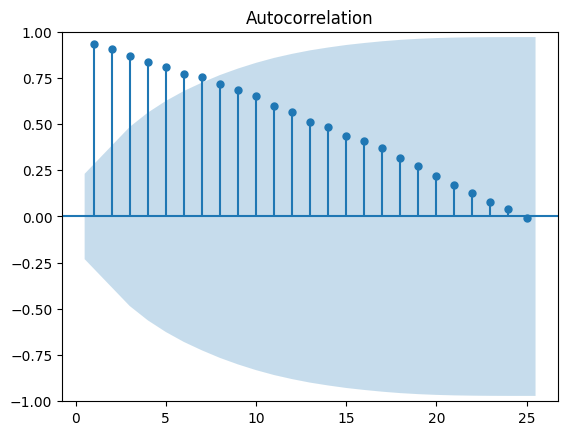

In [34]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Create the figure and axis
fig, ax = plt.subplots()

plot_acf(df, lags=25, zero=False, ax=ax)

# Show the plot
plt.show()


In [35]:

df_1 = df.diff().dropna()


In [36]:
# Subtract the rolling mean (e.g., 12-period rolling mean)
df_diff = df_1-df_1.rolling(window=12).mean()

df_diff = df_diff.dropna()


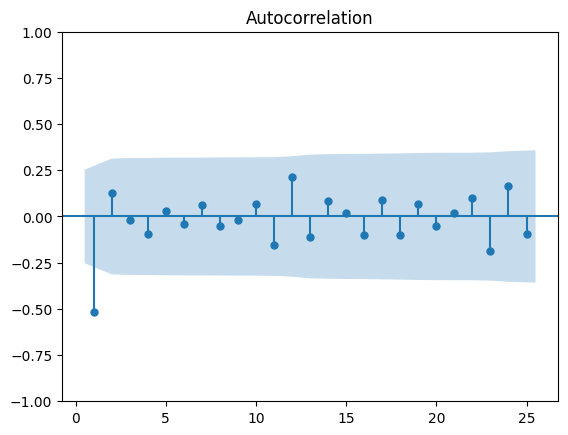

In [37]:

# Create figure and subplots
fig, ax1 = plt.subplots()

# Plot the ACF
plot_acf(df_diff, lags=25, zero=False, ax=ax1)

# Show figure
plt.show()

In [38]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(df_diff)
print("ADF Statistic:", result[0])
print("p-value:", result[1])  # should be < 0.05


ADF Statistic: -8.076563527537823
p-value: 1.5000134196812526e-12


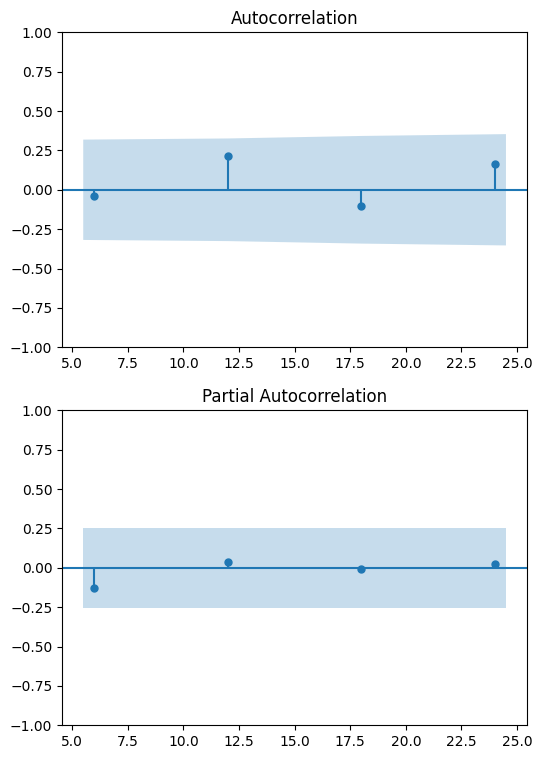

In [39]:
# Make list of first 5 seasonal lags (multiples of 12 months)
lags = [6, 12, 18, 24]

# Create the figure 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 9))

# Plot the ACF on ax1
plot_acf(df_diff, lags=lags, zero=False, ax=ax1)

# Plot the PACF on ax2
plot_pacf(df_diff, lags=lags, zero=False, ax=ax2)

plt.show()


In [40]:
import pmdarima as pm
model = pm.auto_arima(df_diff,
                       seasonal=True, 
                        m=12,     
                       d=0,
                       D=0,               # Differencing orders
                       start_p=0, 
                       start_q=0,
                       max_p=5,  
                       max_q=5,
                       max_P=5, 
                       max_Q=5,
                       trace=True,
                       error_action='ignore',
                       suppress_warnings=True,
                      stepwise=True,
                       information_criterion='aic')

print(model.summary())


Performing stepwise search to minimize aic
 ARIMA(0,0,0)(1,0,1)[12] intercept   : AIC=1594.017, Time=0.11 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=1597.667, Time=0.01 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=1578.415, Time=0.07 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=1574.379, Time=0.09 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=1595.667, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : AIC=1580.354, Time=0.02 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : AIC=1574.848, Time=0.11 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : AIC=1575.994, Time=0.14 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : AIC=1572.888, Time=0.07 sec
 ARIMA(0,0,1)(2,0,0)[12] intercept   : AIC=1574.851, Time=0.12 sec
 ARIMA(0,0,1)(2,0,1)[12] intercept   : AIC=1576.848, Time=0.22 sec
 ARIMA(0,0,0)(1,0,0)[12] intercept   : AIC=1592.717, Time=0.05 sec
 ARIMA(1,0,1)(1,0,0)[12] intercept   : AIC=1574.772, Time=0.11 sec
 ARIMA(0,0,2)(1,0,0)[12] intercept   : AIC=1577.638, Time=0.13 sec
 ARIMA(1,0,2)(1,0,0

In [41]:
# Import model class
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Create model object
model = SARIMAX(df_diff, 
                order=(2, 0, 1), 
                seasonal_order=(0, 0, 3, 12)  # assuming monthly seasonality
)

# Fit model
results = model.fit()



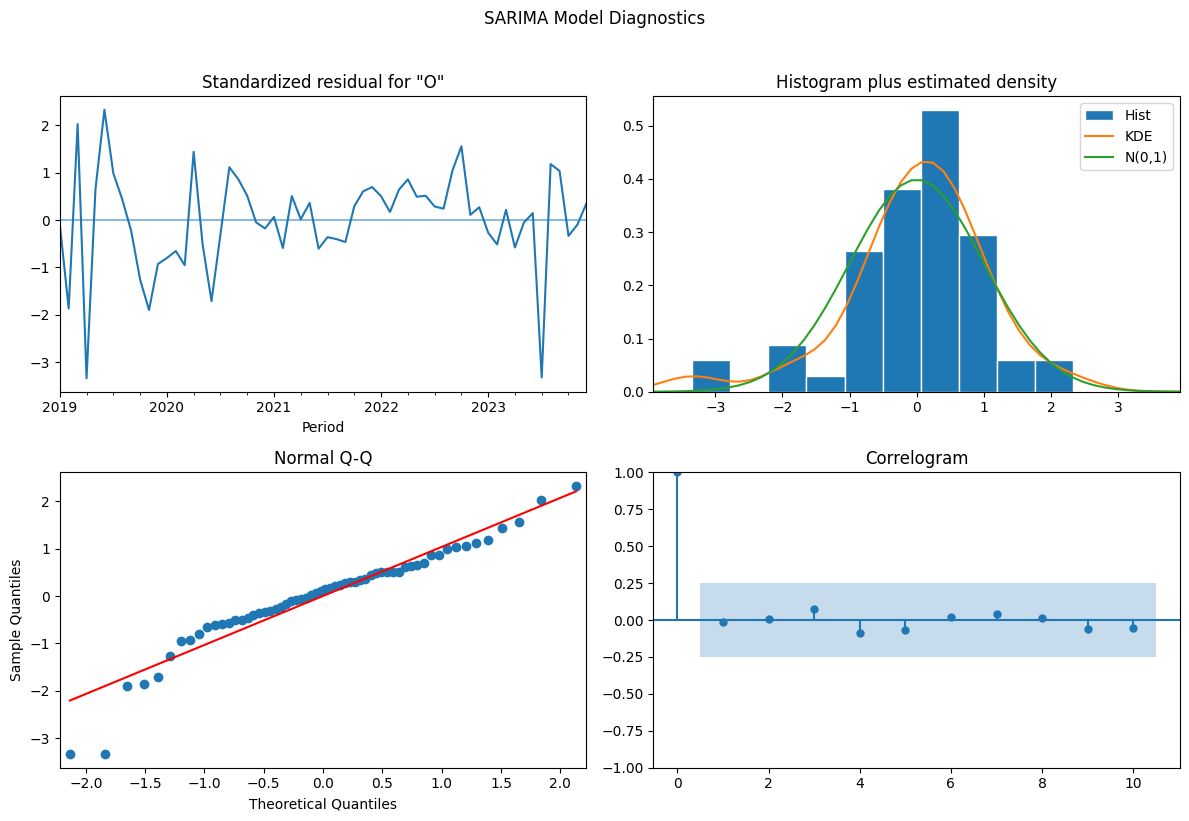

In [42]:
# 4) In‑sample diagnostics ─────────────────────────────────────────────────
results.plot_diagnostics(figsize=(12,8))
plt.suptitle("SARIMA Model Diagnostics", y=1.02)
plt.tight_layout()
plt.show()



In [43]:
start = df_diff.index[-20]
forecast_object = results.get_prediction(start=start)


# Extract predicted mean values
mean = forecast_object.predicted_mean

# Get confidence intervals
conf_int = forecast_object.conf_int()

# Get the prediction dates
dates = mean.index


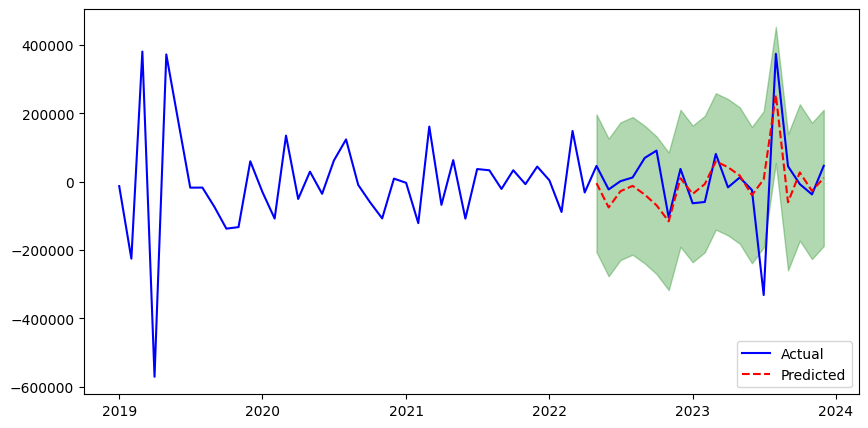

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Plot original data
plt.plot(df_diff.index, df_diff, label='Actual',color='blue')

# Plot predicted mean
plt.plot(dates, mean, label='Predicted', color='red',linestyle='--')

# Plot confidence interval
plt.fill_between(dates, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='green', alpha=0.3)

plt.legend()
plt.show()


In [45]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import matplotlib.pyplot as plt

# 1. Extract predicted values
forecast_values = mean

# 2. Extract actual values for the same forecast period
actual_values = df_diff.loc[forecast_values.index]

# 3. Compute residuals
residuals = actual_values - forecast_values

# 4. Compute metrics
mae = mean_absolute_error(actual_values, forecast_values)
mape = mean_absolute_percentage_error(actual_values, forecast_values)

# 5. Print results
print(f"Forecast MAE: {mae:.2f}")
print(f"Forecast MAPE: {mape*100 :.2f}%")




Forecast MAE: 64432.77
Forecast MAPE: 216.08%


In [46]:
# Create forecast object
forecast_object = results.get_forecast(steps=30)

# Extract predicted mean attribute
mean = forecast_object.predicted_mean

# Calculate the confidence intervals
conf_int = forecast_object.conf_int()

# Extract the forecast dates
dates = mean.index


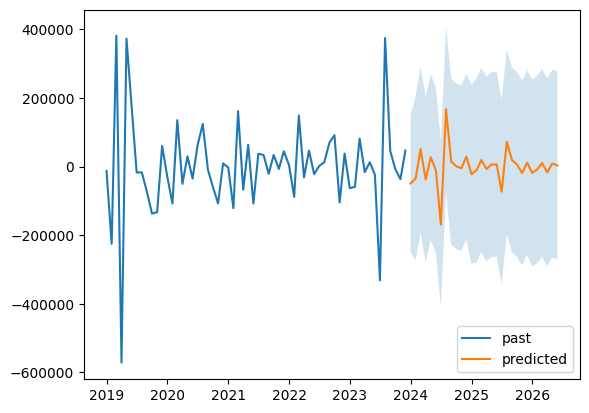

In [47]:
plt.figure()

plt.plot(df_diff.index, df_diff, label='past')

# Plot the prediction means as a line
plt.plot(dates, mean, label='predicted') 

# Shade the area between the confidence intervals
plt.fill_between(dates, conf_int.iloc[:, 0], conf_int.iloc[:, 1], alpha=0.2)

# Plot legend and show figure
plt.legend()
plt.show()


In [48]:
## Print last predicted mean
print(mean.iloc[-1])

# Print last confidence interval
print(conf_int.iloc[-1])


2868.45527036586
lower Oil Production(bbl)   -270788.562294
upper Oil Production(bbl)    276525.472834
Name: 2026-06-01 00:00:00, dtype: float64


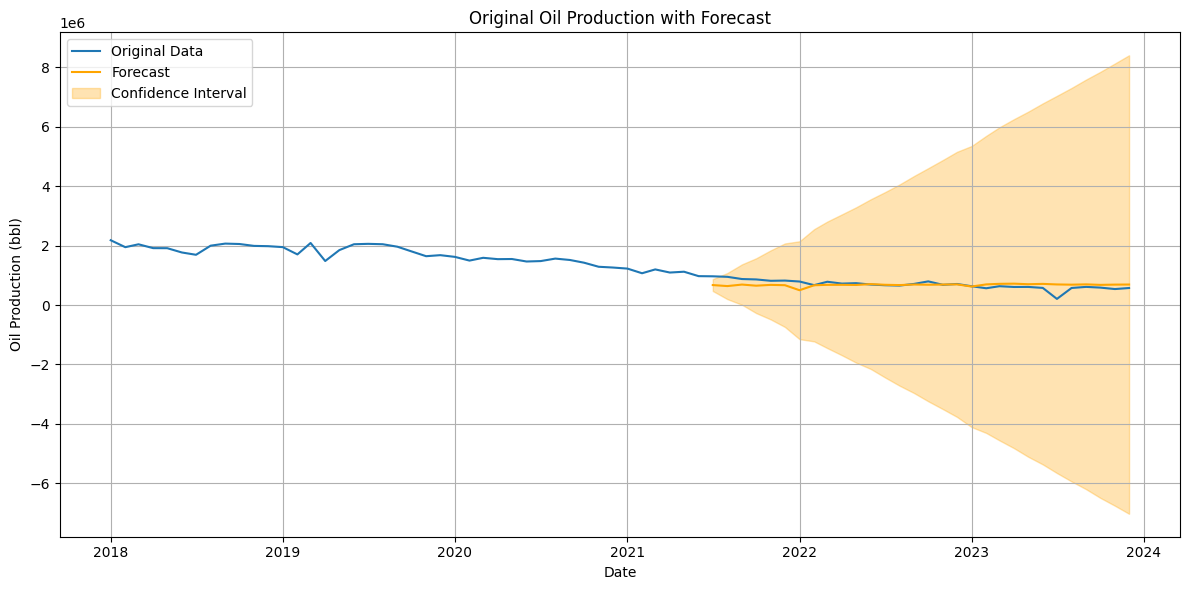

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# 1. Last observed original value before forecast begins
last_observed_value = df['Oil Production(bbl)'].iloc[-21]  # Adjust for start=-20

# 2. Invert the differencing (cumulative sum + last original)
forecast_original = mean.cumsum() + last_observed_value

# 3. Re-align index of forecast to original df
forecast_original.index = df.index[-len(forecast_original):]

# 4. Invert confidence intervals
conf_int_original = conf_int.cumsum()
conf_int_original.index = forecast_original.index
conf_int_original += last_observed_value

# 5. Plot
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Oil Production(bbl)'], label='Original Data')
plt.plot(forecast_original.index, forecast_original, label='Forecast', color='orange')

# Plot confidence intervals
plt.fill_between(forecast_original.index,
                 conf_int_original.iloc[:, 0],
                 conf_int_original.iloc[:, 1],
                 color='orange', alpha=0.3, label='Confidence Interval')

# Decorations
plt.title("Original Oil Production with Forecast")
plt.xlabel("Date")
plt.ylabel("Oil Production (bbl)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [34]:
print("dtype:", raw_y.dtype)
print("non‑NA count:", raw_y.count())


dtype: int64
non‑NA count: 72


In [35]:
y = raw_y.dropna()


In [37]:
n_test = 12
if len(y) <= n_test:
    raise ValueError(f"Only {len(y)} points—can’t reserve {n_test} for test.")

y_train = y.iloc[:-n_test]
y_test  = y.iloc[-n_test:]

print("Train samples:", len(y_train))
print("Test  samples:", len(y_test))
print("Train head:\n", y_train.head())
print("Train tail:\n", y_train.tail())


Train samples: 60
Test  samples: 12
Train head:
 Period
2018-01-01    2181529
2018-02-01    1947711
2018-03-01    2044780
2018-04-01    1915683
2018-05-01    1913518
Freq: MS, Name: Oil Production(bbl), dtype: int64
Train tail:
 Period
2022-08-01    654716
2022-09-01    710913
2022-10-01    796677
2022-11-01    680780
2022-12-01    708937
Freq: MS, Name: Oil Production(bbl), dtype: int64


In [38]:
# 3) AUTO‑ARIMA with seasonality ──────────────────────────────────────────
# We’ll search (p,d,q) × (P,D,Q,12) automatically:
auto_sarima = pm.auto_arima(
    y_train,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,                # let it choose
    seasonal=True,
    m=12,                  # monthly seasonality
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,                # let it choose
    trace=True,            # prints progress
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True,
    information_criterion='aic'
)

print(auto_sarima.summary())  
# You’ll see something like SARIMA( p,d,q )x(P,D,Q,12)



Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1572.085, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1567.720, Time=0.09 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1569.094, Time=0.25 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1571.866, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=1565.928, Time=0.03 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=1567.666, Time=0.10 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=1569.423, Time=0.18 sec
 ARIMA(2,1,0)(0,0,0)[12] intercept   : AIC=1567.478, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=1566.741, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=1567.604, Time=0.03 sec
 ARIMA(2,1,1)(0,0,0)[12] intercept   : AIC=1568.719, Time=0.14 sec
 ARIMA(1,1,0)(0,0,0)[12]             : AIC=1565.106, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12]             : AIC=1566.931, Time=0.15 sec
 ARIMA(1,1,0)(0,0,1)[12]             : AIC=1566.934, Time=0.09 sec
 ARIMA(1,1,0)(1,0,1

In [40]:
# 5) Forecast next 12 periods (with confidence intervals) ─────────────────
n_steps = n_test
fc, conf_int = auto_sarima.predict(
    n_periods=n_steps,
    return_conf_int=True,
    alpha=0.05
)
fc_index = pd.date_range(start=y_train.index[-1] + y_train.index.freq,
                         periods=n_steps, freq=y_train.index.freq)
fc_series    = pd.Series(fc, index=fc_index)
ci_lower     = pd.Series(conf_int[:, 0], index=fc_index)
ci_upper     = pd.Series(conf_int[:, 1], index=fc_index)



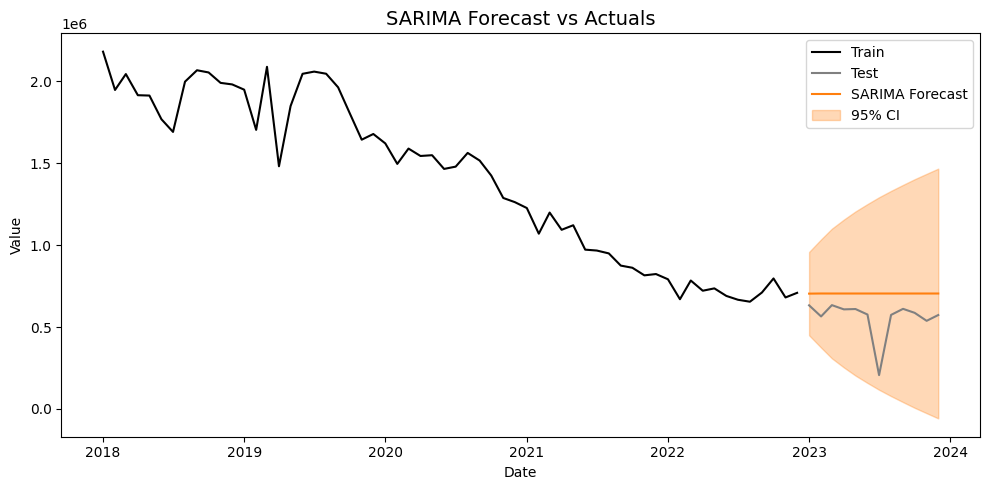

In [41]:
# 6) Plot observed vs forecast on ORIGINAL scale ──────────────────────────
plt.figure(figsize=(10,5))
plt.plot(y_train.index, y_train, label='Train', color='black')
plt.plot(y_test.index,  y_test,  label='Test',  color='gray')
plt.plot(fc_series.index, fc_series, label='SARIMA Forecast', color='C1')

# shade the confidence interval
plt.fill_between(fc_index, ci_lower, ci_upper,
                 color='C1', alpha=0.3, label='95% CI')

plt.title("SARIMA Forecast vs Actuals", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()



In [42]:
# 7) Compute out‑of‑sample MAPE ────────────────────────────────────────────
mape = mean_absolute_percentage_error(y_test, fc_series) * 100
print(f"Out‑of‑sample MAPE: {mape:.2f}%")



Out‑of‑sample MAPE: 37.87%


In [43]:
# 8) (Optional) Refit SARIMAX via statsmodels for deeper control ───────────
# If you want custom settings (e.g. enforce_stationarity=False), grab orders:
p, d, q      = auto_sarima.order
P, D, Q, m   = auto_sarima.seasonal_order

sarimax = SARIMAX(
    y_train,
    order=(p, d, q),
    seasonal_order=(P, D, Q, m),
    enforce_stationarity=False,
    enforce_invertibility=False
)
sarimax_res = sarimax.fit(disp=False)
print(sarimax_res.summary())



                                SARIMAX Results                                
Dep. Variable:     Oil Production(bbl)   No. Observations:                   60
Model:                SARIMAX(1, 1, 0)   Log Likelihood                -765.134
Date:                 Sun, 20 Jul 2025   AIC                           1534.268
Time:                         10:14:49   BIC                           1538.389
Sample:                     01-01-2018   HQIC                          1535.874
                          - 12-01-2022                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4125      0.067     -6.188      0.000      -0.543      -0.282
sigma2      1.682e+10   6.37e-13   2.64e+22      0.000    1.68e+10    1.68e+10
Ljung-Box (L1) (Q):                   0.24  

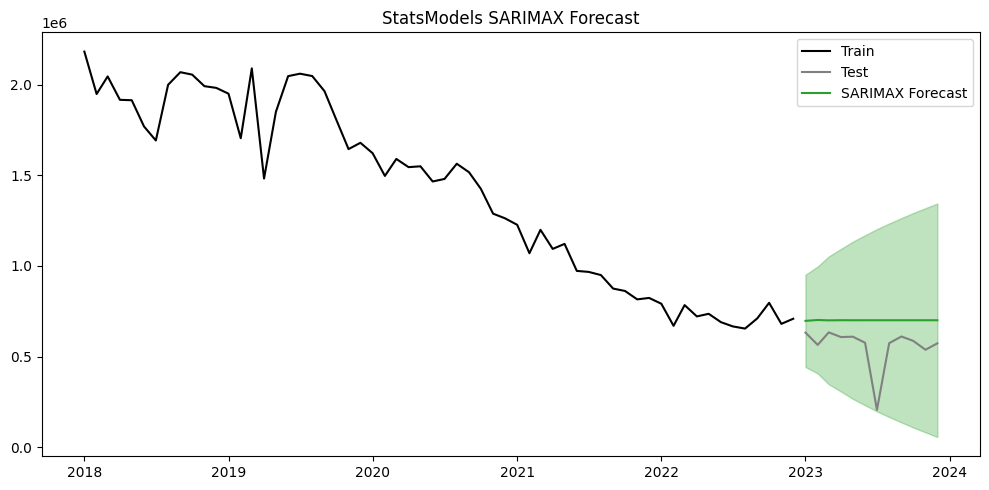

In [45]:
# Forecast with statsmodels
sarimax_fc = sarimax_res.get_forecast(steps=n_steps)
sm_fc      = sarimax_fc.predicted_mean
sm_ci      = sarimax_fc.conf_int(alpha=0.05)

# Plot it
plt.figure(figsize=(10,5))
plt.plot(y_train, 'k', label='Train')
plt.plot(y_test,  '0.5', label='Test')
plt.plot(sm_fc,   'C2', label='SARIMAX Forecast')
plt.fill_between(sm_ci.index,
                 sm_ci.iloc[:,0], sm_ci.iloc[:,1],
                 color='C2', alpha=0.3)
plt.title("StatsModels SARIMAX Forecast")
plt.legend()

plt.tight_layout()
plt.show()
